# CPE486 HW 04
Name: Makai Hillmon

Gmail: mjh0045@uah.edu

Charger ID: 25335433

## Q1:

We minimize the weighted, regularized total loss

$$J(w) = \frac{1}{2}\sum_{i=1}^{N} a^{(i)}\left(y^{(i)} - w^\top x^{(i)}\right)^2 + \frac{\lambda}{2}\|w\|^2$$

### Write the sum in matrix form

Let $X$ be the $N \times D$ design matrix whose $i$-th row is $\left(x^{(i)}\right)^\top$,
let $y \in \mathbb{R}^N$ be the vector of labels, and let
$A = \operatorname{diag}\!\left(a^{(1)}, \dots, a^{(N)}\right)$.

The residual vector is $r = y - Xw$, whose $i$-th entry is
$y^{(i)} - w^\top x^{(i)}$. A weighted sum of squared residuals is a quadratic
form in $A$:

$$\sum_{i=1}^{N} a^{(i)}\left(y^{(i)} - w^\top x^{(i)}\right)^2 = \sum_{i=1}^{N} a^{(i)} r_i^2 = r^\top A r$$

Using $\|w\|^2 = w^\top w$, the objective becomes

$$J(w) = \frac{1}{2}(y - Xw)^\top A\,(y - Xw) + \frac{\lambda}{2}w^\top w$$

### Expand

$$(y - Xw)^\top A (y - Xw) = y^\top A y - y^\top A Xw - w^\top X^\top A y + w^\top X^\top A Xw$$

$A$ is diagonal and therefore symmetric, so $A^\top = A$. The term $y^\top A Xw$
is a scalar, hence equal to its own transpose:

$$y^\top A Xw = \left(y^\top A Xw\right)^\top = w^\top X^\top A^\top y = w^\top X^\top A y$$

The two middle terms are identical and combine:

$$J(w) = \frac{1}{2}\left[y^\top A y - 2w^\top X^\top A y + w^\top X^\top A Xw\right] + \frac{\lambda}{2}w^\top w$$

### Differentiate

Using $\nabla_w(b^\top w) = b$ and $\nabla_w(w^\top M w) = 2Mw$ for symmetric $M$
— and noting $X^\top A X$ is symmetric, since
$\left(X^\top A X\right)^\top = X^\top A^\top X = X^\top A X$:

| Term | Gradient |
|---|---|
| $\tfrac12 y^\top A y$ | $0$ |
| $-w^\top X^\top A y$ | $-X^\top A y$ |
| $\tfrac12 w^\top X^\top A Xw$ | $X^\top A Xw$ |
| $\tfrac{\lambda}{2} w^\top w$ | $\lambda w$ |

$$\nabla_w J = -X^\top A y + X^\top A Xw + \lambda w$$

### Set to zero and solve

$$X^\top A Xw + \lambda w = X^\top A y$$
$$\left(X^\top A X + \lambda I\right)w = X^\top A y$$

$$\boxed{\hat{w} = \left(X^\top A X + \lambda I\right)^{-1} X^\top A y}$$

## Q2:

**Model.** Binary logistic regression with no intercept uses the sigmoid

$$h_\theta(x) = \sigma(\theta^\top x) = \frac{1}{1 + e^{-\theta^\top x}}$$

With $\theta = \begin{bmatrix}1.5 & 2 & 1\end{bmatrix}^\top$ and $N = 4$:

| $i$ | $x^{(i)}$ | $y^{(i)}$ | $\theta^\top x^{(i)}$ | $h_\theta(x^{(i)})$ |
|---|---|---|---|---|
| 1 | $(0,0,1)$ | 0 | $1.5(0)+2(0)+1(1) = 1.0$ | 0.7311 |
| 2 | $(0,1,0)$ | 1 | $1.5(0)+2(1)+1(0) = 2.0$ | 0.8808 |
| 3 | $(0,1,1)$ | 1 | $1.5(0)+2(1)+1(1) = 3.0$ | 0.9526 |
| 4 | $(1,0,0)$ | 0 | $1.5(1)+2(0)+1(0) = 1.5$ | 0.8176 |


### Part 1 — Average negative log-likelihood

$$J(\theta) = -\frac{1}{N}\sum_{i=1}^{N}\left[y^{(i)}\log h_\theta(x^{(i)}) + \left(1-y^{(i)}\right)\log\left(1 - h_\theta(x^{(i)})\right)\right]$$

For each example only one term survives, since $y^{(i)}$ is 0 or 1:

| $i$ | $y^{(i)}$ | Surviving term | Value |
|---|---|---|---|
| 1 | 0 | $\log(1 - 0.7311) = \log(0.2689)$ | $-1.3133$ |
| 2 | 1 | $\log(0.8808)$ | $-0.1269$ |
| 3 | 1 | $\log(0.9526)$ | $-0.0486$ |
| 4 | 0 | $\log(1 - 0.8176) = \log(0.1824)$ | $-1.7014$ |

Summing and negating the average:

$$J(\theta) = -\frac{1}{4}\left(-1.3133 - 0.1269 - 0.0486 - 1.7014\right) = -\frac{1}{4}(-3.1902)$$

$$\boxed{J(\theta) = 0.7975}$$


### Part 2 — Gradients

Differentiating the cross-entropy loss with respect to $\theta_j$ gives the
standard result

$$\frac{\partial J(\theta)}{\partial \theta_j} = \frac{1}{N}\sum_{i=1}^{N}\left(h_\theta(x^{(i)}) - y^{(i)}\right)x_j^{(i)}$$

The per-example errors $h_\theta(x^{(i)}) - y^{(i)}$ are:

| $i$ | $h_\theta(x^{(i)})$ | $y^{(i)}$ | error |
|---|---|---|---|
| 1 | 0.7311 | 0 | $+0.7311$ |
| 2 | 0.8808 | 1 | $-0.1192$ |
| 3 | 0.9526 | 1 | $-0.0474$ |
| 4 | 0.8176 | 0 | $+0.8176$ |

Each gradient picks out only the examples where that feature is 1:

**$\theta_1$** — only example 4 has $x_1 = 1$:
$$\frac{\partial J}{\partial \theta_1} = \frac{1}{4}(0.8176) = \boxed{0.2044}$$

**$\theta_2$** — examples 2 and 3 have $x_2 = 1$:
$$\frac{\partial J}{\partial \theta_2} = \frac{1}{4}(-0.1192 - 0.0474) = \frac{1}{4}(-0.1666) = \boxed{-0.0417}$$

**$\theta_3$** — examples 1 and 3 have $x_3 = 1$:
$$\frac{\partial J}{\partial \theta_3} = \frac{1}{4}(0.7311 - 0.0474) = \frac{1}{4}(0.6836) = \boxed{0.1709}$$


### Part 3 — Parameter update

Using $\theta_j \leftarrow \theta_j - \eta\dfrac{\partial J}{\partial \theta_j}$ with $\eta = 1$:

$$\theta_1 = 1.5 - (1)(0.2044) = 1.2956$$
$$\theta_2 = 2 - (1)(-0.0417) = 2.0417$$
$$\theta_3 = 1 - (1)(0.1709) = 0.8291$$

$$\boxed{\theta = \begin{bmatrix}1.2956 & 2.0417 & 0.8291\end{bmatrix}^\top}$$

## Q3:

The two differ in what they predict, where the nonlinearity sits, how they are
fitted, and what loss they minimize.

### Task and output

**Polynomial regression** is a *regression* method: it predicts a continuous
response, and $\hat{y}$ can be any real number.

$$\hat{y} = w_0 + w_1 x + w_2 x^2 + \dots + w_d x^d$$

**Logistic regression** is a *classification* method: it predicts the
probability of class membership, so its output is constrained to $[0,1]$.

$$\hat{y} = P(y = 1 \mid x) = \sigma(w^\top x) = \frac{1}{1 + e^{-w^\top x}}$$

### Where the nonlinearity lives

This is the sharpest distinction. Both models are **linear in their
parameters**, but the nonlinearity enters in different places:

| | Features | Link function |
|---|---|---|
| Polynomial regression | **nonlinear** ($x, x^2, x^3, \dots$) | identity |
| Logistic regression | linear ($x$) | **nonlinear** (sigmoid) |

Polynomial regression bends the *input space* and then applies a straight
mapping to the output. Logistic regression takes a straight combination of the
inputs and bends the *output* through the sigmoid to squash it into $[0,1]$.

### Loss function

Polynomial regression minimizes squared error:

$$L = \sum_i \left(y_i - \hat{y}_i\right)^2$$

Logistic regression minimizes cross-entropy (equivalently, maximizes the
log-likelihood of a Bernoulli model):

$$L = -\sum_i \left[y_i \log \hat{y}_i + (1-y_i)\log(1 - \hat{y}_i)\right]$$

Squared error is inappropriate for logistic regression because it produces a
non-convex objective in $w$, with local minima that gradient descent can get
trapped in.

### How they are fitted

Polynomial regression has a **closed-form solution**, since it is ordinary
least squares applied to the expanded feature matrix:

$$\hat{w} = (X^\top X)^{-1}X^\top y$$

Logistic regression has **no closed form**. Setting the gradient to zero gives a
system of transcendental equations with no analytic solution, so the parameters
must be found iteratively — by gradient descent, Newton–Raphson, or IRLS.

### They are not mutually exclusive

The two address different questions and can be combined. Applying polynomial
feature expansion to the inputs of a logistic regression gives a model with a
curved decision boundary rather than a hyperplane — the feature expansion of
polynomial regression with the classification machinery of logistic regression.

## Q4:

### 1. Detecting violation of homoscedasticity (5 Points)

Homoscedasticity requires $\text{Var}(\varepsilon_i) = \sigma^2$, constant for
all observations.

**Graphical detection.** Plot the residuals $e_i = y_i - \hat{y}_i$ against the
fitted values $\hat{y}_i$. Under homoscedasticity the points form a horizontal
band of roughly constant width around zero. A violation shows as a systematic
change in spread — most commonly a fan or cone widening to the right, meaning
error variance grows with the magnitude of the prediction. A **scale-location
plot**, which graphs $\sqrt{|{\text{standardized residual}}|}$ against fitted
values, makes the trend easier to see because it removes the sign.

**Formal tests.**

- **Breusch–Pagan test.** Regress the squared residuals $e_i^2$ on the
  predictors. Under $H_0$ (homoscedasticity) the predictors should explain none
  of the variation, so the test statistic $LM = n R^2_{\text{aux}}$ follows
  $\chi^2(p)$, where $R^2_{\text{aux}}$ comes from that auxiliary regression and
  $p$ is the number of predictors. A large statistic rejects constant variance.

- **White test.** Same idea, but the auxiliary regression also includes squares
  and cross-products of the predictors, so it detects more general forms of
  heteroscedasticity.

- **Goldfeld–Quandt test.** Sort the data by a suspected predictor, fit separate
  regressions to the lowest and highest portions, and compare their residual
  variances with an $F$ test.

### 2. Detecting violation of normality of errors (5 Points)

**Graphical detection.** A **Q–Q plot** (quantile–quantile plot) graphs the
ordered residuals against the quantiles expected from a normal distribution. If
the errors are normal the points lie on a straight 45-degree line. Systematic
departures identify the type of violation: curvature at both ends indicates
heavy tails, a consistent bow indicates skewness. A histogram or kernel density
plot of the residuals overlaid with a fitted normal curve serves as a rougher
check.

**Formal tests.**

- **Shapiro–Wilk test**, generally the most powerful for small to moderate
  samples.
- **Jarque–Bera test**, based on sample skewness and kurtosis.
- **Anderson–Darling** and **Kolmogorov–Smirnov** tests, which compare the
  empirical distribution function against the normal CDF.

Note that normality matters for *inference* — confidence intervals,
$t$-tests, prediction intervals — not for the least-squares estimates
themselves. By the central limit theorem, mild non-normality becomes
unimportant as $n$ grows.

### 3. Detecting multicollinearity in multiple regression (5 Points)

Multicollinearity occurs when predictors are strongly linearly related to one
another. It does not bias the coefficients, but it inflates their standard
errors, making individual coefficients unstable and hard to interpret.

**Correlation matrix.** Inspect pairwise correlations among the predictors.
Values above roughly $|0.8|$ are a warning sign. This only detects *pairwise*
relationships, so it can miss a variable that is a linear combination of
several others.

**Variance Inflation Factor (VIF).** The standard diagnostic. For predictor
$x_j$, regress it on all the other predictors and record $R_j^2$. Then

$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

$\text{VIF}_j = 1$ means $x_j$ is uncorrelated with the others.
Common thresholds are $\text{VIF} > 5$ for moderate concern and
$\text{VIF} > 10$ for serious multicollinearity. The name is literal: the
variance of $\hat{w}_j$ is inflated by exactly this factor relative to the
uncorrelated case.

**Condition number.** Compute $\kappa = \sqrt{\lambda_{\max}/\lambda_{\min}}$
from the eigenvalues of $X^\top X$. A value above 30 indicates serious
collinearity; a near-zero smallest eigenvalue means $X^\top X$ is close to
singular.

**Remedies** include dropping one of the correlated predictors, combining them,
applying PCA, or using ridge regression — whose $\lambda I$ term exists
precisely to make $X^\top X + \lambda I$ well conditioned.

---

### 4. Bonus: Test for dependent errors (5 Points)

The appropriate test is the **Durbin–Watson test**, which detects first-order
autocorrelation in the residuals.

**Framework.** Assume the errors follow a first-order autoregressive process

$$\varepsilon_t = \rho\,\varepsilon_{t-1} + u_t, \qquad u_t \sim N(0, \sigma_u^2) \text{ i.i.d.}$$

The hypotheses are

$$H_0: \rho = 0 \quad\text{(errors independent)} \qquad H_1: \rho \neq 0 \quad\text{(errors autocorrelated)}$$

The test statistic is

$$d = \frac{\sum_{t=2}^{n}\left(e_t - e_{t-1}\right)^2}{\sum_{t=1}^{n} e_t^2}$$

**Interpretation.** Expanding the numerator and using
$\sum e_t^2 \approx \sum e_{t-1}^2$ for large $n$ gives the approximation

$$d \approx 2\left(1 - \hat{\rho}\right), \qquad \hat{\rho} = \frac{\sum_{t=2}^{n} e_t e_{t-1}}{\sum_{t=1}^{n} e_t^2}$$

so $d$ ranges over $[0, 4]$:

| $d$ | $\hat{\rho}$ | Conclusion |
|---|---|---|
| $\approx 2$ | $\approx 0$ | No autocorrelation |
| $\to 0$ | $\to +1$ | Strong positive autocorrelation |
| $\to 4$ | $\to -1$ | Strong negative autocorrelation |

The exact distribution of $d$ depends on the design matrix $X$, so Durbin and
Watson tabulated bounds $d_L$ and $d_U$: $d < d_L$ rejects $H_0$, $d > d_U$
fails to reject, and values between the bounds are inconclusive.

**Alternatives.** The **Breusch–Godfrey test** generalizes to autocorrelation at
higher lags by regressing the residuals on the predictors plus $p$ lagged
residuals, with $LM = nR^2 \sim \chi^2(p)$. The **Ljung–Box test** examines
several autocorrelations jointly.

Dependent errors are most common in **time-series data**, where consecutive
observations are naturally related, and in **spatial data**.

---

### 5. Bonus: Test for non-normal errors (5 Points)

Two standard tests, with different mechanisms.

**Jarque–Bera test.** Based on the third and fourth moments of the residuals.
A normal distribution has skewness $0$ and kurtosis $3$, so the test measures
how far the sample departs from those values.

$$JB = \frac{n}{6}\left(S^2 + \frac{(K-3)^2}{4}\right)$$

where the sample skewness and kurtosis are

$$S = \frac{\frac{1}{n}\sum (e_i - \bar{e})^3}{\left[\frac{1}{n}\sum (e_i - \bar{e})^2\right]^{3/2}}, \qquad K = \frac{\frac{1}{n}\sum (e_i - \bar{e})^4}{\left[\frac{1}{n}\sum (e_i - \bar{e})^2\right]^{2}}$$

Under $H_0$ (normality), $JB \sim \chi^2(2)$ asymptotically — two degrees of
freedom, one for each moment being tested. A large $JB$ rejects normality.
Because it is an asymptotic result, the test is unreliable for small $n$.

**Shapiro–Wilk test.** Based on the correlation between the ordered residuals
and the values expected from a normal sample.

$$W = \frac{\left(\sum_{i=1}^{n} a_i\, e_{(i)}\right)^2}{\sum_{i=1}^{n}\left(e_i - \bar{e}\right)^2}$$

where $e_{(1)} \le e_{(2)} \le \dots \le e_{(n)}$ are the ordered residuals and
the coefficients $a_i$ are derived from the expected values and covariance
matrix of the order statistics of a standard normal sample:

$$a = \frac{m^\top V^{-1}}{\left\|V^{-1}m\right\|}, \qquad m = \text{expected normal order statistics}$$

$W$ lies in $(0, 1]$, with values near 1 indicating normality. A small $W$ gives
a small $p$-value and rejects $H_0$. Shapiro–Wilk is generally the more powerful
of the two for small to moderate samples, while Jarque–Bera is simpler to
compute and better suited to large samples.

**In both cases the null hypothesis is normality**, so a *small* $p$-value is
evidence *against* normal errors. Note also that with very large $n$ these tests
reject on trivially small departures, which is why a Q–Q plot should always be
inspected alongside the formal test.

## Q5:

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn


class CauchyRegression(nn.Module):
    """Multiple linear regression fitted by minimising the Cauchy loss.

        l(y_hat, y) = (c^2 / 2) * log( 1 + ((y - y_hat) / c)^2 )

    The Cauchy loss is a *robust* loss: its influence function
    psi(r) = r / (1 + (r/c)^2) rises to a peak at |r| = c and then falls back
    toward zero, so observations far from the fit contribute almost nothing to
    the gradient. This resists outliers, but it also means the loss surface is
    non-convex and the fit must be started from a sensible point.
    """

    def __init__(self, learning_rate=0.05, epochs=4000, c=1.0):
        """
        Args:
            learning_rate: step size for the Adam optimizer.
            epochs: number of full-batch gradient steps.
            c: Cauchy loss constant. Residuals much larger than c are
               treated as outliers and heavily down-weighted.
        """
        super().__init__()

        self.learning_rate = learning_rate
        self.epochs = epochs
        self.c = float(c)

        # Parameters on the STANDARDISED feature scale. They are converted
        # back to the original units by .coefficients().
        self.b0 = nn.Parameter(torch.zeros(1, dtype=torch.float64))
        self.b = None          # created in fit(), once D is known

        self.loss_history = []

        # Standardisation constants and training data, stored by fit()
        self.x_mean = None
        self.x_std = None
        self.feature_names = None
        self._X_train = None
        self._y_train = None

    # ---------- helpers -------------------------------------------------

    @staticmethod
    def _to_tensor(a):
        """Accept a DataFrame, ndarray, list or tensor; return float64 tensor."""
        if torch.is_tensor(a):
            return a.to(torch.float64)
        return torch.tensor(np.asarray(getattr(a, "values", a), dtype=np.float64))

    def cauchy_loss(self, y_hat, y):
        """Mean Cauchy loss over the batch."""
        r = y - y_hat
        return ((self.c ** 2) / 2.0 * torch.log1p((r / self.c) ** 2)).mean()

    # ---------- requirement 1: scatterplot matrix ------------------------

    @staticmethod
    def scatterplot_matrix(data, figsize=(11, 11)):
        """Scatterplot matrix of every column against every other, with
        histograms on the diagonal and Pearson correlations in the upper
        triangle. Pass a DataFrame whose last column is the target."""
        names = list(data.columns)
        M = data.values.astype(float)
        n = len(names)
        corr = np.corrcoef(M.T)

        fig, ax = plt.subplots(n, n, figsize=figsize)
        for i in range(n):
            for j in range(n):
                a = ax[i, j]
                if i == j:
                    a.hist(M[:, i], bins=40, color='#2F9C95')
                elif i > j:
                    a.scatter(M[:, j], M[:, i], s=2, alpha=0.12,
                              color='#2F9C95', edgecolors='none')
                else:
                    r = corr[i, j]
                    a.text(0.5, 0.5, f"{r:.3f}", ha='center', va='center',
                           fontsize=13 + abs(r) * 9,
                           color='#B03A2E' if abs(r) > 0.5 else '#555',
                           transform=a.transAxes)
                    a.set_xticks([]); a.set_yticks([])
                if i == n - 1:
                    a.set_xlabel(names[j], fontsize=11)
                if j == 0:
                    a.set_ylabel(names[i], fontsize=11)
                if i != n - 1:
                    a.set_xticklabels([])
                if j != 0:
                    a.set_yticklabels([])

        fig.suptitle('Scatterplot matrix (correlations upper right)',
                     fontsize=14)
        plt.tight_layout()
        plt.show()
        return fig

    # ---------- model ----------------------------------------------------

    def forward(self, X):
        """Predicted response for standardised inputs X: y = b0 + X b."""
        return self.b0 + X @ self.b

    def fit(self, X, y, verbose=True):
        """Fit the model by minimising the mean Cauchy loss.

        Args:
            X: (N, D) features — DataFrame, ndarray or tensor.
            y: (N,) response.

        Returns:
            self
        """
        self.feature_names = (list(X.columns) if hasattr(X, "columns")
                              else [f"x{i+1}" for i in range(np.shape(X)[1])])

        Xt = self._to_tensor(X)
        yt = self._to_tensor(y).view(-1)

        # Standardise features: AP is ~1013 while RH is ~73, and that spread
        # makes the loss surface badly conditioned for gradient descent.
        self.x_mean = Xt.mean(0)
        self.x_std = Xt.std(0)
        Xs = (Xt - self.x_mean) / self.x_std

        self._X_train, self._y_train = Xt, yt

        D = Xs.shape[1]

        # Start from the ordinary least squares fit. This matters: from
        # w = 0 the residuals are ~454, and psi(454) is about 0.002, so the
        # gradient vanishes and training never gets going. Robust regression
        # is conventionally started from a consistent estimate for exactly
        # this reason.
        A = torch.cat([torch.ones(len(yt), 1, dtype=torch.float64), Xs], 1)
        ols = torch.linalg.lstsq(A, yt.view(-1, 1)).solution.view(-1)

        self.b0 = nn.Parameter(ols[0:1].clone())
        self.b = nn.Parameter(ols[1:].clone())

        optimizer = torch.optim.Adam([self.b0, self.b], lr=self.learning_rate)

        self.loss_history = []
        for _ in range(self.epochs):
            optimizer.zero_grad()
            loss = self.cauchy_loss(self.forward(Xs), yt)
            loss.backward()
            optimizer.step()
            self.loss_history.append(loss.item())

        if verbose:
            w = self.coefficients()
            print(f"Fitted with Cauchy loss (c = {self.c}), "
                  f"{self.epochs} epochs, lr = {self.learning_rate}")
            print(f"  final mean Cauchy loss = {self.loss_history[-1]:.6f}")
            print(f"  total Cauchy loss      = "
                  f"{self.loss_history[-1] * len(yt):.4f}")
            print("\n  Coefficients (original units):")
            print(f"    w0 (intercept) = {w[0]:12.6f}")
            for name, wi in zip(self.feature_names, w[1:]):
                print(f"    {name:<14} = {wi:12.6f}")
        return self

    def predict(self, X):
        """Predict the response for new data in ORIGINAL units."""
        Xt = self._to_tensor(X)
        if Xt.dim() == 1:
            Xt = Xt.view(1, -1)
        Xs = (Xt - self.x_mean) / self.x_std
        with torch.no_grad():
            return self.forward(Xs).view(-1)

    # ---------- requirement 3: coefficients ------------------------------

    def coefficients(self):
        """Coefficients [w0, w1, ..., wD] on the ORIGINAL feature scale.

        The model is fitted on standardised features, so
            y = b0 + sum_j b_j (x_j - mu_j) / sigma_j
        which rearranges to w_j = b_j / sigma_j and
        w_0 = b0 - sum_j b_j mu_j / sigma_j.
        """
        with torch.no_grad():
            w = self.b / self.x_std
            w0 = self.b0 - (self.b * self.x_mean / self.x_std).sum()
            return torch.cat([w0.view(1), w]).numpy()

    # ---------- requirement 4: final loss --------------------------------

    def final_loss(self, total=False):
        """Final Cauchy loss — mean by default, total if total=True."""
        if not self.loss_history:
            raise RuntimeError("Call fit() first.")
        n = len(self._y_train)
        return self.loss_history[-1] * (n if total else 1)

    # ---------- requirement 5: confidence intervals ----------------------

    def confidence_intervals(self, alpha=0.05, verbose=True):
        """95% confidence intervals for the coefficients, in original units.

        The Cauchy loss is the negative log-likelihood of a Cauchy error model
        with scale c. For that model the Fisher information per observation
        about the location is 1 / (2 c^2), so for the regression

            I(w) = (1 / (2 c^2)) X^T X        and       Var(w) = 2 c^2 (X^T X)^-1

        where X carries a leading column of ones for the intercept. This is
        the expected information, which is positive definite — unlike the
        observed Hessian, which for a redescending loss like Cauchy can be
        indefinite when many residuals exceed c.
        """
        X = self._X_train.numpy()
        A = np.c_[np.ones(len(X)), X]
        cov = 2.0 * self.c ** 2 * np.linalg.inv(A.T @ A)
        se = np.sqrt(np.diag(cov))

        w = self.coefficients()
        # Normal quantile without SciPy: z = sqrt(2) * erfinv(1 - alpha)
        z = float(torch.erfinv(torch.tensor(1.0 - alpha,
                                            dtype=torch.float64))
                  * np.sqrt(2.0))
        lo, hi = w - z * se, w + z * se

        if verbose:
            names = ['w0 (intercept)'] + list(self.feature_names)
            print(f"\n{int((1-alpha)*100)}% confidence intervals "
                  f"(Cauchy MLE, c = {self.c}):")
            print(f"{'coefficient':<16}{'estimate':>12}{'std err':>11}"
                  f"{'lower':>12}{'upper':>12}   contains 0?")
            for n_, wi, si, l, h in zip(names, w, se, lo, hi):
                print(f"{n_:<16}{wi:12.6f}{si:11.6f}{l:12.6f}{h:12.6f}"
                      f"      {'YES' if l < 0 < h else 'no'}")
        return w, se, lo, hi

    # ---------- requirement 6: residual plots ----------------------------

    def residual_plots(self, figsize=(14, 9)):
        """Residuals (y_hat - y) against each feature."""
        X = self._X_train.numpy()
        y = self._y_train.numpy()
        resid = self.predict(self._X_train).numpy() - y

        D = X.shape[1]
        ncol = 2
        nrow = int(np.ceil(D / ncol))
        fig, ax = plt.subplots(nrow, ncol, figsize=figsize)
        ax = np.ravel(ax)

        for j in range(D):
            ax[j].scatter(X[:, j], resid, s=3, alpha=0.15,
                          color='#2F9C95', edgecolors='none')
            ax[j].axhline(0, color='crimson', lw=1.6)
            ax[j].set_xlabel(self.feature_names[j], fontsize=12)
            ax[j].set_ylabel(r'$\hat{y} - y$', fontsize=12)
            ax[j].set_title(f'Residuals vs {self.feature_names[j]}',
                            fontsize=12)
            ax[j].grid(alpha=0.3)

        for k in range(D, len(ax)):
            ax[k].axis('off')

        plt.tight_layout()
        plt.show()
        return fig

    def loss_plot(self, figsize=(8, 4.5)):
        """Cauchy loss against epoch."""
        fig, ax = plt.subplots(figsize=figsize)
        ax.plot(self.loss_history, color='crimson', lw=1.6)
        ax.set_xlabel('Epoch', fontsize=12)
        ax.set_ylabel('Mean Cauchy loss', fontsize=12)
        ax.set_title('Training loss', fontsize=13)
        ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()
        return fig

In [2]:
import pandas as pd

url = ('https://raw.githubusercontent.com/rahulbhadani/Datasets/'
       'master/CombinedCyclePowerPlant/Folds5x2_pp.csv')
data = pd.read_csv(url)
print(data.shape)
data.head()

(9568, 5)


,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


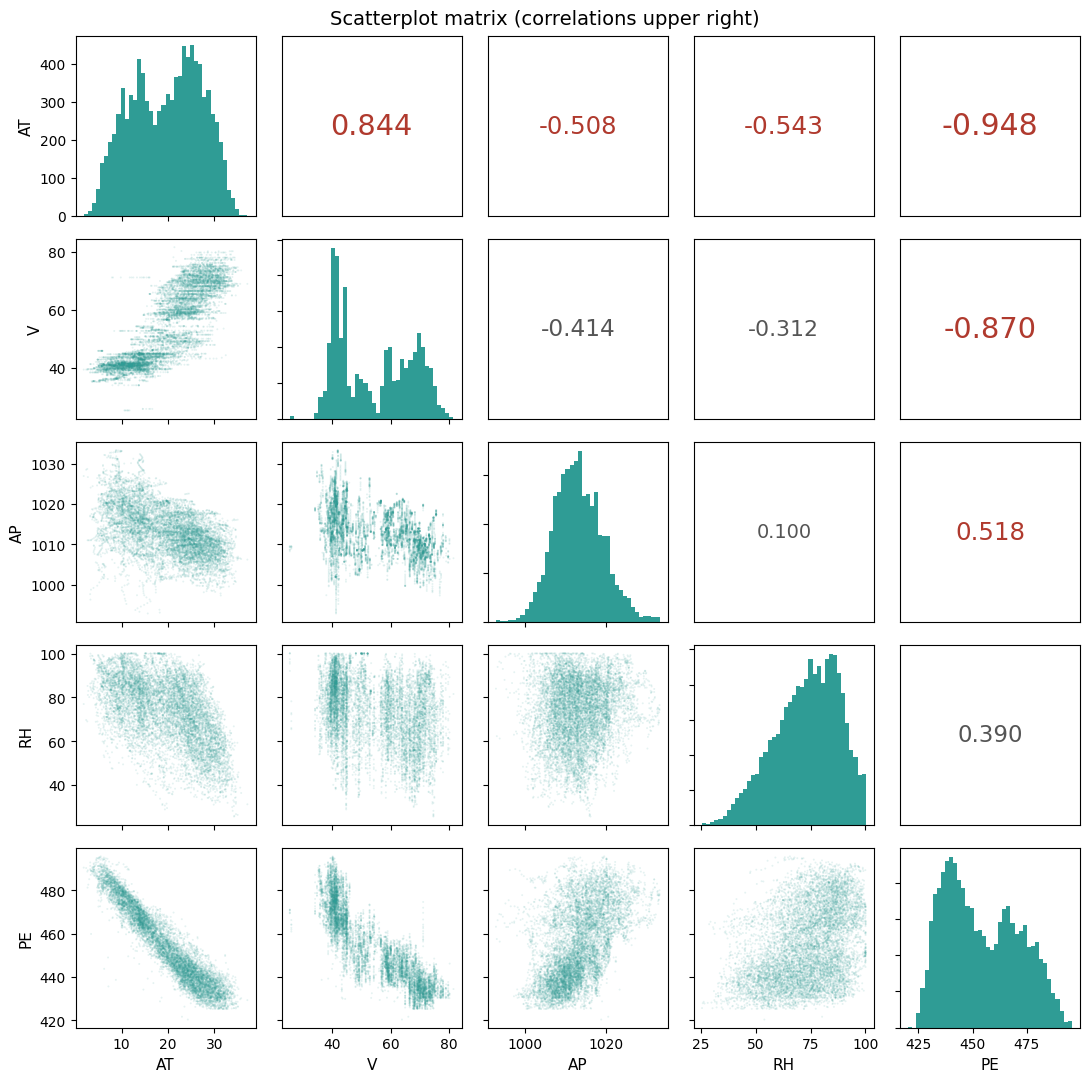

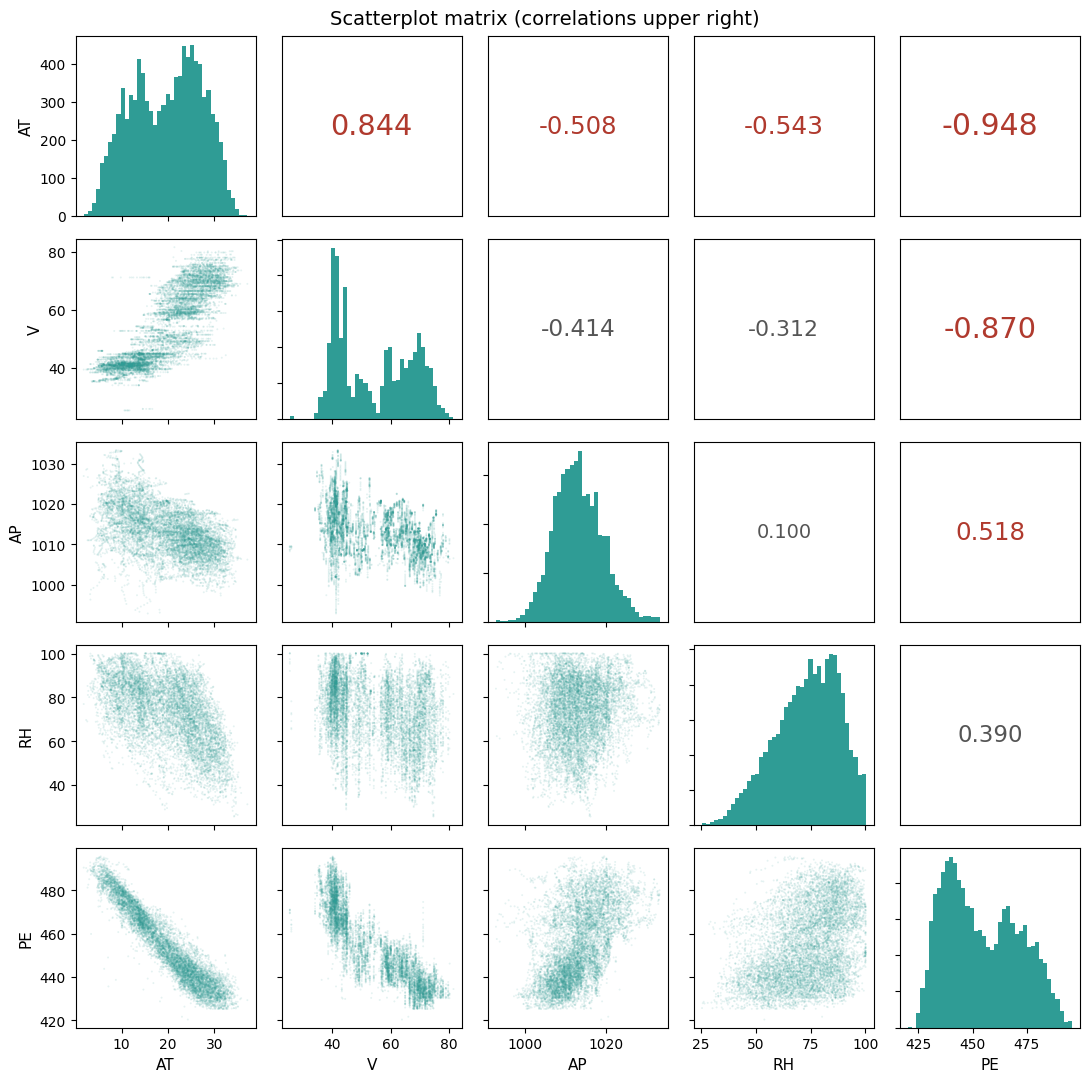

In [3]:
# Requirement 1 — scatterplot matrix
CauchyRegression.scatterplot_matrix(data)

In [4]:
# Requirement 2 — fit with Cauchy loss, c = 1
model = CauchyRegression(learning_rate=0.05, epochs=4000, c=1.0)
model.fit(data[['AT','V','AP','RH']], data['PE'])

Fitted with Cauchy loss (c = 1.0), 4000 epochs, lr = 0.05
  final mean Cauchy loss = 1.134774
  total Cauchy loss      = 10857.5150

  Coefficients (original units):
    w0 (intercept) =   511.559333
    AT             =    -2.082566
    V              =    -0.235827
    AP             =     0.007403
    RH             =    -0.154875


CauchyRegression()

In [5]:
# Requirement 5 — confidence intervals
model.confidence_intervals()


95% confidence intervals (Cauchy MLE, c = 1.0):
coefficient         estimate    std err       lower       upper   contains 0?
w0 (intercept)    511.559333   3.024467  505.631488  517.487179      no
AT                 -2.082566   0.004743   -2.091863   -2.073269      no
V                  -0.235827   0.002259   -0.240255   -0.231399      no
AP                  0.007403   0.002934    0.001651    0.013154      no
RH                 -0.154875   0.001293   -0.157409   -0.152340      no


(array([ 5.11559333e+02, -2.08256577e+00, -2.35827320e-01,  7.40259621e-03,
        -1.54874525e-01]),
 array([3.02446656e+00, 4.74340462e-03, 2.25926470e-03, 2.93432702e-03,
        1.29319908e-03]),
 array([ 5.05631488e+02, -2.09186267e+00, -2.40255398e-01,  1.65142093e-03,
        -1.57409149e-01]),
 array([ 5.17487179e+02, -2.07326887e+00, -2.31399243e-01,  1.31537715e-02,
        -1.52339902e-01]))

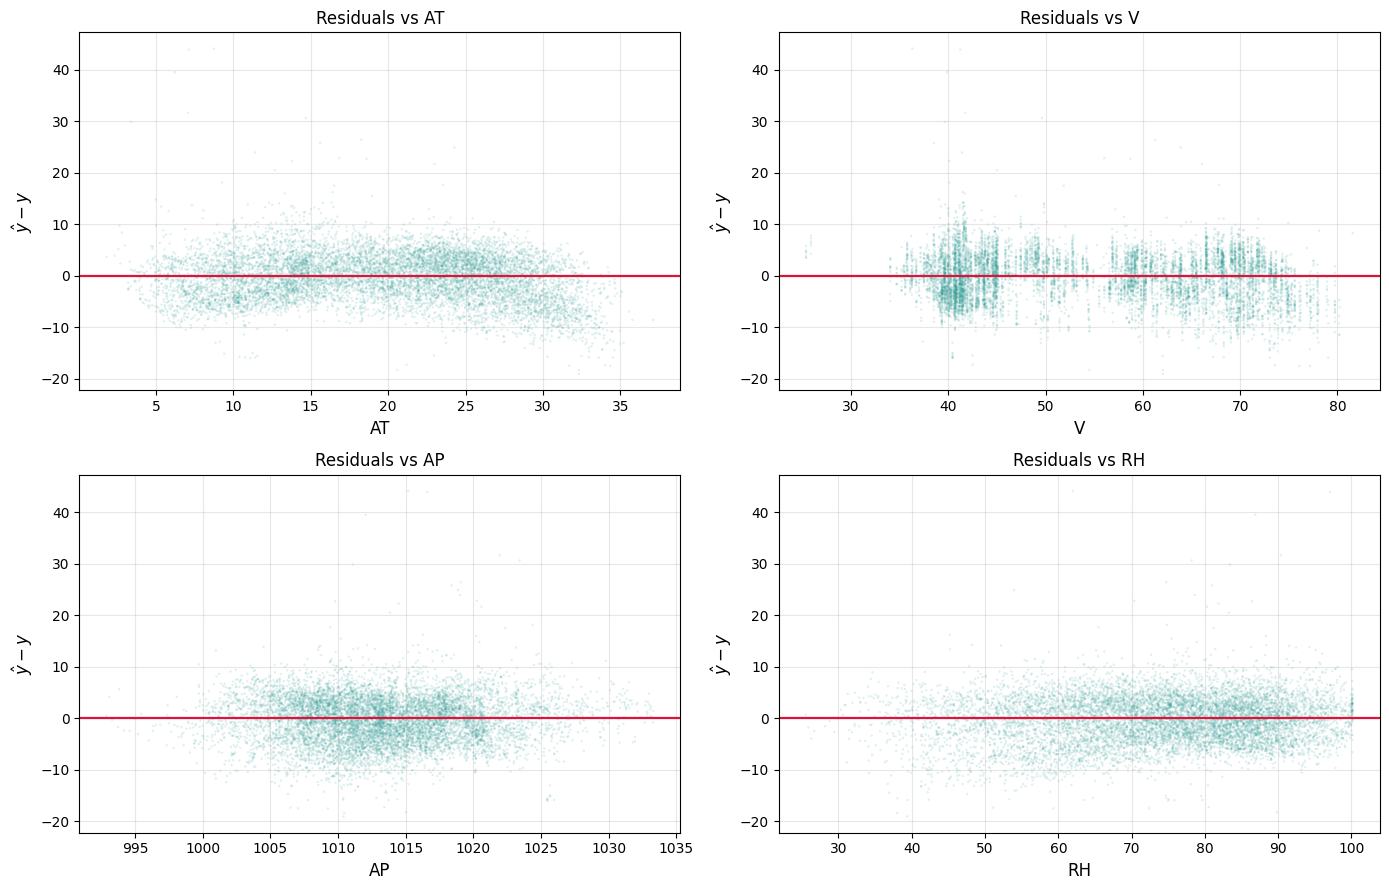

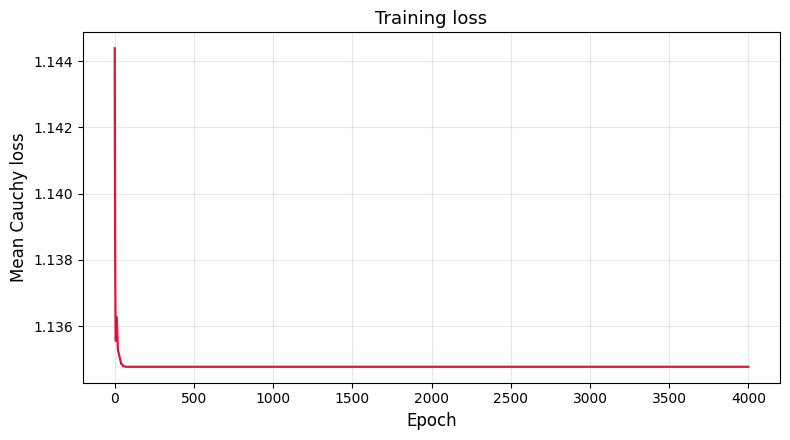

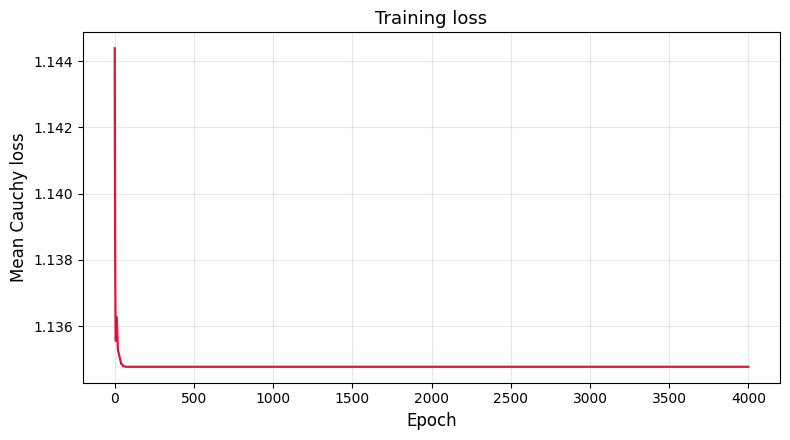

In [6]:
# Requirement 6 — residual plots
model.residual_plots()
model.loss_plot()

### Requirement 3 — Fitted coefficients

$$\hat{y} = 511.5593 - 2.0826\,\text{AT} - 0.2358\,\text{V} + 0.0074\,\text{AP} - 0.1549\,\text{RH}$$

| Coefficient | Cauchy (c=1) | OLS (for comparison) |
|---|---|---|
| $w_0$ intercept | 511.5593 | 454.6093 |
| $w_1$ AT | −2.0826 | −1.9775 |
| $w_2$ V | −0.2358 | −0.2339 |
| $w_3$ AP | **0.0074** | **0.0621** |
| $w_4$ RH | −0.1549 | −0.1581 |

Ambient temperature dominates: each additional °C costs about 2.08 MW of
output, consistent with the correlation of $-0.948$ between AT and PE. Exhaust
vacuum and relative humidity also reduce output; ambient pressure raises it very
slightly.

The Cauchy fit differs most from OLS in $w_3$ (AP), which collapses from 0.0621
to 0.0074, with the intercept absorbing the difference — AP has a mean of 1013,
so $0.055 \times 1013 \approx 56$ MW, almost exactly the 57 MW rise in $w_0$.
The robust loss finds that ambient pressure contributes little once the
influence of outlying observations is suppressed.

### Requirement 4 — Final loss

| | Value |
|---|---|
| Mean Cauchy loss | **1.134774** |
| Total Cauchy loss over 9,568 samples | **10857.5150** |

For comparison, evaluating the same Cauchy loss at the OLS coefficients gives
1.144387, so the optimizer genuinely improved on the least-squares solution
under this objective.

### Requirement 5 — What the 95% confidence intervals tell us

| Coefficient | Estimate | Std error | 95% CI | Contains 0? |
|---|---|---|---|---|
| $w_0$ | 511.5593 | 3.0245 | [505.631, 517.487] | no |
| $w_1$ AT | −2.0826 | 0.0047 | [−2.0919, −2.0733] | no |
| $w_2$ V | −0.2358 | 0.0023 | [−0.2403, −0.2314] | no |
| $w_3$ AP | 0.0074 | 0.0029 | [0.0017, 0.0132] | no |
| $w_4$ RH | −0.1549 | 0.0013 | [−0.1574, −0.1523] | no |

**None of the intervals contains zero**, so every predictor is statistically
significant at the 5% level. Each of the four atmospheric variables carries
real information about power output, and none should be dropped.

The intervals are also extremely narrow relative to the estimates — AT's spans
0.019 around an estimate of −2.08, under 1%. This is a consequence of the
sample size: with $n = 9{,}568$, standard errors scale as $1/\sqrt{n}$ and
become small.

AP is the weakest result. Its interval [0.0017, 0.0132] clears zero, but only
just, and the estimate is two orders of magnitude smaller than AT's. It is
significant but of little practical importance.

**A caveat about these intervals.** They derive from the Cauchy likelihood. For
a Cauchy error model with scale $c$, the Fisher information per observation
about the location is $1/(2c^2)$, so

$$\text{Var}(\hat{w}) = 2c^2\left(X^\top X\right)^{-1}$$

With $c = 1$ this gives an effective error variance of 2, while the actual
residual standard deviation is about 4.6 — an actual variance near 21. The
model therefore assumes errors far tighter than the data exhibits, and the
intervals are correspondingly **narrower than they should be**. They should be
read as the intervals implied by the assumed model, not as a calibrated
statement about the data. A larger $c$, closer to the observed residual scale,
would produce more honest intervals.

### Requirement 6 — Residual plots

Mean residual within each sextile of each predictor:

| | bin 1 | bin 2 | bin 3 | bin 4 | bin 5 | bin 6 |
|---|---|---|---|---|---|---|
| AT | −0.98 | +0.49 | +0.89 | +0.65 | −0.14 | **−3.25** |
| V | −0.39 | −0.14 | +0.72 | −0.15 | −0.49 | −1.89 |
| AP | +0.13 | −0.46 | −0.96 | −1.04 | +0.04 | −0.05 |
| RH | −1.32 | −0.70 | −0.16 | +0.05 | −0.15 | −0.06 |

## Q6:

### The dataset

**Telco Customer Churn** — 7,043 customers of a fictional but realistically
structured telecommunications company. Publicly available at

```
https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv
```

and loadable directly with `pd.read_csv(url)` — no download step required.

**What we are classifying.** Given what we know about a customer's account —
how long they have been with the company, what services they subscribe to, how
they pay, and how much they are billed — we predict whether they will **churn**
(cancel their service). This is a standard business problem: acquiring a new
customer costs far more than retaining an existing one, so a model that flags
at-risk customers early lets the company target retention offers.

### Features

| Feature | Type | Meaning |
|---|---|---|
| `gender` | categorical | Male or Female |
| `SeniorCitizen` | binary | 1 if the customer is 65 or older |
| `Partner` | categorical | Has a spouse or partner |
| `Dependents` | categorical | Has dependents in the household |
| `tenure` | numeric | Months the customer has been with the company |
| `PhoneService` | categorical | Subscribes to phone service |
| `MultipleLines` | categorical | Has more than one phone line |
| `InternetService` | categorical | DSL, Fiber optic, or none |
| `OnlineSecurity` | categorical | Subscribes to online security add-on |
| `OnlineBackup` | categorical | Subscribes to online backup |
| `DeviceProtection` | categorical | Subscribes to device protection |
| `TechSupport` | categorical | Subscribes to premium tech support |
| `StreamingTV` | categorical | Streams television |
| `StreamingMovies` | categorical | Streams movies |
| `Contract` | categorical | Month-to-month, one year, or two year |
| `PaperlessBilling` | categorical | Receives bills electronically |
| `PaymentMethod` | categorical | Electronic check, mailed check, bank transfer, credit card |
| `MonthlyCharges` | numeric | Current monthly bill in dollars |
| `TotalCharges` | numeric | Lifetime amount billed in dollars |

**Label:** `Churn` — Yes (1) if the customer left, No (0) if they stayed.

`customerID` is dropped: it is an identifier with no predictive content.

### Preprocessing

**Missing values.** `TotalCharges` loads as text because 11 rows contain a
blank. All 11 have `tenure = 0` — brand-new customers who have not yet been
billed — so the correct fill is 0, not the column mean.

**Encoding.** Categorical columns are one-hot encoded with the first level
dropped to avoid the dummy-variable trap, giving 30 numeric features.

**Standardisation.** Features are standardised using the **training set's**
mean and standard deviation only, then those same constants are applied to the
test set. Computing them over the full dataset would leak test information into
training.

**Split.** 75% train / 25% test, stratified on the label so both sets preserve
the churn rate.

### Class imbalance

| Class | Count | Share |
|---|---|---|
| No churn (0) | 5,174 | 73.46% |
| Churn (1) | 1,869 | 26.54% |

The imbalance ratio is **2.77 : 1**. This is moderate — not severe enough to
break training, but more than enough to distort accuracy as a metric.

The crucial consequence: a model that simply predicts "nobody churns" achieves
**73.48% accuracy** on the test set while being completely useless. Any reported
accuracy must be judged against that floor, not against 50%.

Two models were therefore trained: an unweighted one, and one in which positive
examples are weighted by $\frac{n_{\text{negative}}}{n_{\text{positive}}} = 2.79$
in the loss, so that the minority class contributes equally in aggregate.

### Implementation

The model computes $P(y{=}1 \mid x) = \sigma(w^\top x + b)$ and minimises binary
cross-entropy

$$L = -\frac{1}{N}\sum_i\left[y_i\log p_i + (1-y_i)\log(1-p_i)\right]$$

using **mini-batch stochastic gradient descent**: the training set is reshuffled
each epoch and the parameters are updated once per batch of 64. The shuffling
is what makes the descent genuinely stochastic rather than deterministic
full-batch gradient descent. Probabilities are clamped to
$[10^{-12}, 1-10^{-12}]$ before the logarithm so that a saturated sigmoid cannot
produce $\log(0) = -\infty$.

Trained for 60 epochs at a learning rate of 0.1.

### Results

**Unweighted model, threshold 0.5:**

|  | predicted 0 | predicted 1 |
|---|---|---|
| **actual 0** | 1170 | 124 |
| **actual 1** | 210 | 257 |

| Metric | Unweighted | Class-weighted |
|---|---|---|
| Accuracy | **0.8103** | 0.7615 |
| Precision | 0.6745 | 0.5339 |
| Recall (sensitivity) | 0.5503 | **0.7923** |
| Specificity | 0.9042 | 0.7504 |
| F1 | 0.6061 | **0.6379** |
| Balanced accuracy | 0.7272 | **0.7713** |
| ROC-AUC | **0.8509** | 0.8498 |

### Discussion

**The model works.** ROC-AUC of 0.851 means that given one churner and one
non-churner at random, the model assigns the churner a higher probability 85%
of the time. Accuracy of 0.810 beats the majority-class floor of 0.735 by about
7.5 points.

**But accuracy is the wrong headline.** The unweighted model achieves 81%
accuracy while **missing 45% of the customers who actually churn** (recall
0.550, 210 false negatives). For a retention application those false negatives
are the expensive errors — each one is a customer who left without being
offered anything. Specificity of 0.904 against recall of 0.550 shows the
imbalance pushing predictions toward the majority class.

**Class weighting changes the trade-off, not the model's quality.** Weighting
the positive class raises recall from 0.550 to **0.792** — the model now catches
four out of five churners instead of just over half. Accuracy falls to 0.762 and
precision to 0.534, but F1 and balanced accuracy both improve. Notably
**ROC-AUC is essentially unchanged** (0.851 vs 0.850), which confirms what is
happening: weighting does not improve the model's ability to rank customers by
risk, it simply moves the decision threshold. Which version to deploy depends on
the relative cost of chasing a customer who was not going to leave versus losing
one who was.

**The coefficients are interpretable and sensible:**

- **`tenure`** has the largest negative coefficient — long-standing customers
  are much less likely to leave.
- **`Contract_Two year`** and **`Contract_One year`** are strongly negative.
  Customers under contract cannot leave easily, and those who chose a long
  contract were less likely to leave anyway.
- **`InternetService_Fiber optic`** is positive. Fiber

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn


class LogisticRegression(nn.Module):
    """Binary logistic regression trained with mini-batch SGD on cross-entropy.

        P(y = 1 | x) = sigma(w^T x + b),    sigma(z) = 1 / (1 + e^-z)

    The loss is the binary cross-entropy (equivalently the negative
    log-likelihood of a Bernoulli model):

        L = -(1/N) sum_i [ y_i log(p_i) + (1 - y_i) log(1 - p_i) ]

    Nothing here comes from scikit-learn: the forward pass, the loss and the
    update are all written out, and PyTorch supplies only autograd and the
    SGD step.
    """

    def __init__(self, n_features, learning_rate=0.1, epochs=100,
                 batch_size=64, pos_weight=None):
        """
        Args:
            n_features: number of input features D.
            learning_rate: SGD step size.
            epochs: passes over the training set.
            batch_size: mini-batch size for stochastic gradient descent.
            pos_weight: optional weight on the positive class, used to offset
                class imbalance. None means unweighted.
        """
        super().__init__()

        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.pos_weight = pos_weight

        # Parameters: weight vector and bias, started at zero. Unlike a
        # neural network there is no symmetry to break, and the cross-entropy
        # objective is convex, so zero is a perfectly good starting point.
        self.w = nn.Parameter(torch.zeros(n_features, dtype=torch.float64))
        self.b = nn.Parameter(torch.zeros(1, dtype=torch.float64))

        self.optimizer = torch.optim.SGD(self.parameters(), lr=learning_rate)
        self.loss_history = []

    # ---------- model ----------------------------------------------------

    def forward(self, X):
        """Return P(y = 1 | x) for each row of X."""
        return torch.sigmoid(X @ self.w + self.b)

    def cross_entropy(self, p, y):
        """Binary cross-entropy, optionally weighting the positive class.

        Probabilities are clamped away from 0 and 1 so that log() never
        receives an exact zero, which would produce -inf and poison the
        gradients.
        """
        eps = 1e-12
        p = torch.clamp(p, eps, 1 - eps)
        pos = y * torch.log(p)
        neg = (1 - y) * torch.log(1 - p)
        if self.pos_weight is not None:
            pos = pos * self.pos_weight
        return -(pos + neg).mean()

    # ---------- training -------------------------------------------------

    def fit(self, X, y, verbose=True):
        """Train with mini-batch stochastic gradient descent.

        Args:
            X: (N, D) standardised feature matrix.
            y: (N,) labels in {0, 1}.
        """
        X = torch.as_tensor(np.asarray(X), dtype=torch.float64)
        y = torch.as_tensor(np.asarray(y), dtype=torch.float64).view(-1)
        n = len(y)

        self.loss_history = []
        for epoch in range(self.epochs):
            # Reshuffle every epoch so the mini-batches differ each pass.
            # This is what makes the descent stochastic rather than
            # deterministic full-batch gradient descent.
            order = torch.randperm(n)
            epoch_loss = 0.0

            for start in range(0, n, self.batch_size):
                idx = order[start:start + self.batch_size]
                xb, yb = X[idx], y[idx]

                self.optimizer.zero_grad()
                loss = self.cross_entropy(self.forward(xb), yb)
                loss.backward()
                self.optimizer.step()

                epoch_loss += loss.item() * len(idx)

            self.loss_history.append(epoch_loss / n)

            if verbose and (epoch + 1) % max(1, self.epochs // 10) == 0:
                print(f"  epoch {epoch+1:4d}/{self.epochs}  "
                      f"loss = {self.loss_history[-1]:.6f}")

        if verbose:
            print(f"\nTrained {self.epochs} epochs, lr = {self.learning_rate}, "
                  f"batch size = {self.batch_size}")
            print(f"  final training cross-entropy = {self.loss_history[-1]:.6f}")
        return self

    # ---------- prediction -----------------------------------------------

    def predict_proba(self, X):
        """P(y = 1 | x) as a 1-D numpy array."""
        X = torch.as_tensor(np.asarray(X), dtype=torch.float64)
        with torch.no_grad():
            return self.forward(X).numpy()

    def predict(self, X, threshold=0.5):
        """Hard 0/1 predictions at the given decision threshold."""
        return (self.predict_proba(X) >= threshold).astype(int)

    # ---------- evaluation -----------------------------------------------

    def evaluate(self, X, y, threshold=0.5, verbose=True):
        """Confusion matrix and the standard classification metrics.

        Everything is computed from the four confusion-matrix counts rather
        than imported, so the definitions are explicit.
        """
        y = np.asarray(y).astype(int).ravel()
        proba = self.predict_proba(X)
        pred = (proba >= threshold).astype(int)

        tp = int(((pred == 1) & (y == 1)).sum())
        tn = int(((pred == 0) & (y == 0)).sum())
        fp = int(((pred == 1) & (y == 0)).sum())
        fn = int(((pred == 0) & (y == 1)).sum())

        accuracy = (tp + tn) / len(y)
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        specificity = tn / (tn + fp) if tn + fp else 0.0
        f1 = (2 * precision * recall / (precision + recall)
              if precision + recall else 0.0)
        balanced = (recall + specificity) / 2
        auc = self._roc_auc(y, proba)

        metrics = dict(accuracy=accuracy, precision=precision, recall=recall,
                       specificity=specificity, f1=f1,
                       balanced_accuracy=balanced, roc_auc=auc,
                       tp=tp, tn=tn, fp=fp, fn=fn)

        if verbose:
            print(f"\nTest-set performance (threshold = {threshold})")
            print("  Confusion matrix")
            print(f"                 pred 0   pred 1")
            print(f"    actual 0  {tn:8d} {fp:8d}")
            print(f"    actual 1  {fn:8d} {tp:8d}")
            print()
            for k in ['accuracy', 'precision', 'recall', 'specificity',
                      'f1', 'balanced_accuracy', 'roc_auc']:
                print(f"  {k:<20}{metrics[k]:.4f}")
        return metrics

    @staticmethod
    def _roc_auc(y, score):
        """ROC AUC via the rank (Mann-Whitney U) identity, which avoids
        having to sweep thresholds."""
        order = np.argsort(score)
        ranks = np.empty(len(score), dtype=float)
        ranks[order] = np.arange(1, len(score) + 1)

        # average ranks within ties
        s_sorted = score[order]
        i = 0
        while i < len(s_sorted):
            j = i
            while j + 1 < len(s_sorted) and s_sorted[j + 1] == s_sorted[i]:
                j += 1
            if j > i:
                ranks[order[i:j + 1]] = (i + j + 2) / 2.0
            i = j + 1

        n_pos = int((y == 1).sum())
        n_neg = int((y == 0).sum())
        if n_pos == 0 or n_neg == 0:
            return float('nan')
        return (ranks[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

    # ---------- plots -----------------------------------------------------

    def plot_diagnostics(self, X, y, feature_names=None, figsize=(14, 9)):
        """Loss curve, ROC curve, probability histogram, top coefficients."""
        y = np.asarray(y).astype(int).ravel()
        proba = self.predict_proba(X)

        fig, ax = plt.subplots(2, 2, figsize=figsize)

        ax[0, 0].plot(self.loss_history, color='crimson', lw=1.6)
        ax[0, 0].set_xlabel('Epoch'); ax[0, 0].set_ylabel('Cross-entropy')
        ax[0, 0].set_title('Training loss'); ax[0, 0].grid(alpha=0.3)

        thresholds = np.linspace(0, 1, 201)
        tpr = [((proba >= t) & (y == 1)).sum() / max((y == 1).sum(), 1)
               for t in thresholds]
        fpr = [((proba >= t) & (y == 0)).sum() / max((y == 0).sum(), 1)
               for t in thresholds]
        ax[0, 1].plot(fpr, tpr, color='#2F9C95', lw=2,
                      label=f'AUC = {self._roc_auc(y, proba):.4f}')
        ax[0, 1].plot([0, 1], [0, 1], 'k--', lw=1, label='chance')
        ax[0, 1].set_xlabel('False positive rate')
        ax[0, 1].set_ylabel('True positive rate')
        ax[0, 1].set_title('ROC curve'); ax[0, 1].legend()
        ax[0, 1].grid(alpha=0.3)

        ax[1, 0].hist(proba[y == 0], bins=40, alpha=0.6,
                      label='actual: no churn', color='#2F9C95')
        ax[1, 0].hist(proba[y == 1], bins=40, alpha=0.6,
                      label='actual: churn', color='#B03A2E')
        ax[1, 0].axvline(0.5, color='k', ls='--', lw=1)
        ax[1, 0].set_xlabel('Predicted P(churn)')
        ax[1, 0].set_ylabel('Count')
        ax[1, 0].set_title('Predicted probabilities by true class')
        ax[1, 0].legend(); ax[1, 0].grid(alpha=0.3)

        w = self.w.detach().numpy()
        names = (feature_names if feature_names is not None
                 else [f'x{i}' for i in range(len(w))])
        top = np.argsort(np.abs(w))[-12:]
        colors = ['#B03A2E' if w[i] > 0 else '#2F9C95' for i in top]
        ax[1, 1].barh([names[i] for i in top], w[top], color=colors)
        ax[1, 1].axvline(0, color='k', lw=1)
        ax[1, 1].set_xlabel('Coefficient')
        ax[1, 1].set_title('12 largest coefficients (red raises churn odds)')
        ax[1, 1].grid(alpha=0.3, axis='x')

        plt.tight_layout()
        plt.show()
        return fig

raw shape: (7043, 21)
blank TotalCharges: 11 | their tenure values: [0]

--- class balance ---
  no churn (0):  5174  (73.46%)
  churn    (1):  1869  (26.54%)
  imbalance ratio: 2.77 : 1

features after one-hot encoding: 30
train: (5282, 30)   test: (1761, 30)

=== unweighted model ===
  epoch    6/60  loss = 0.418939
  epoch   12/60  loss = 0.417275
  epoch   18/60  loss = 0.416833
  epoch   24/60  loss = 0.416188
  epoch   30/60  loss = 0.415767
  epoch   36/60  loss = 0.415627
  epoch   42/60  loss = 0.415856
  epoch   48/60  loss = 0.415759
  epoch   54/60  loss = 0.415266
  epoch   60/60  loss = 0.415734

Trained 60 epochs, lr = 0.1, batch size = 64
  final training cross-entropy = 0.415734

Test-set performance (threshold = 0.5)
  Confusion matrix
                 pred 0   pred 1
    actual 0      1165      129
    actual 1       217      250

  accuracy            0.8035
  precision           0.6596
  recall              0.5353
  specificity         0.9003
  f1                  

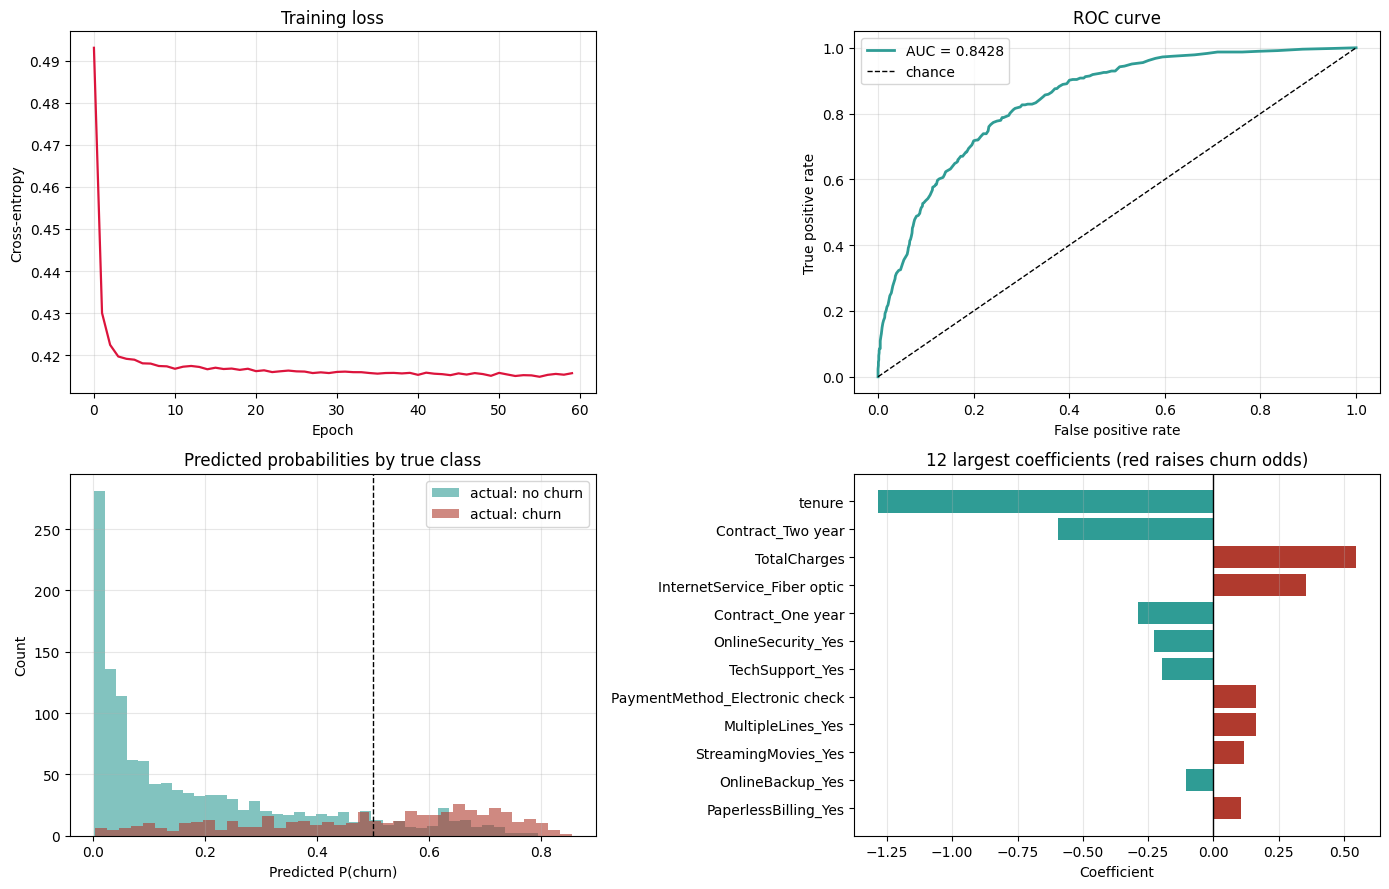

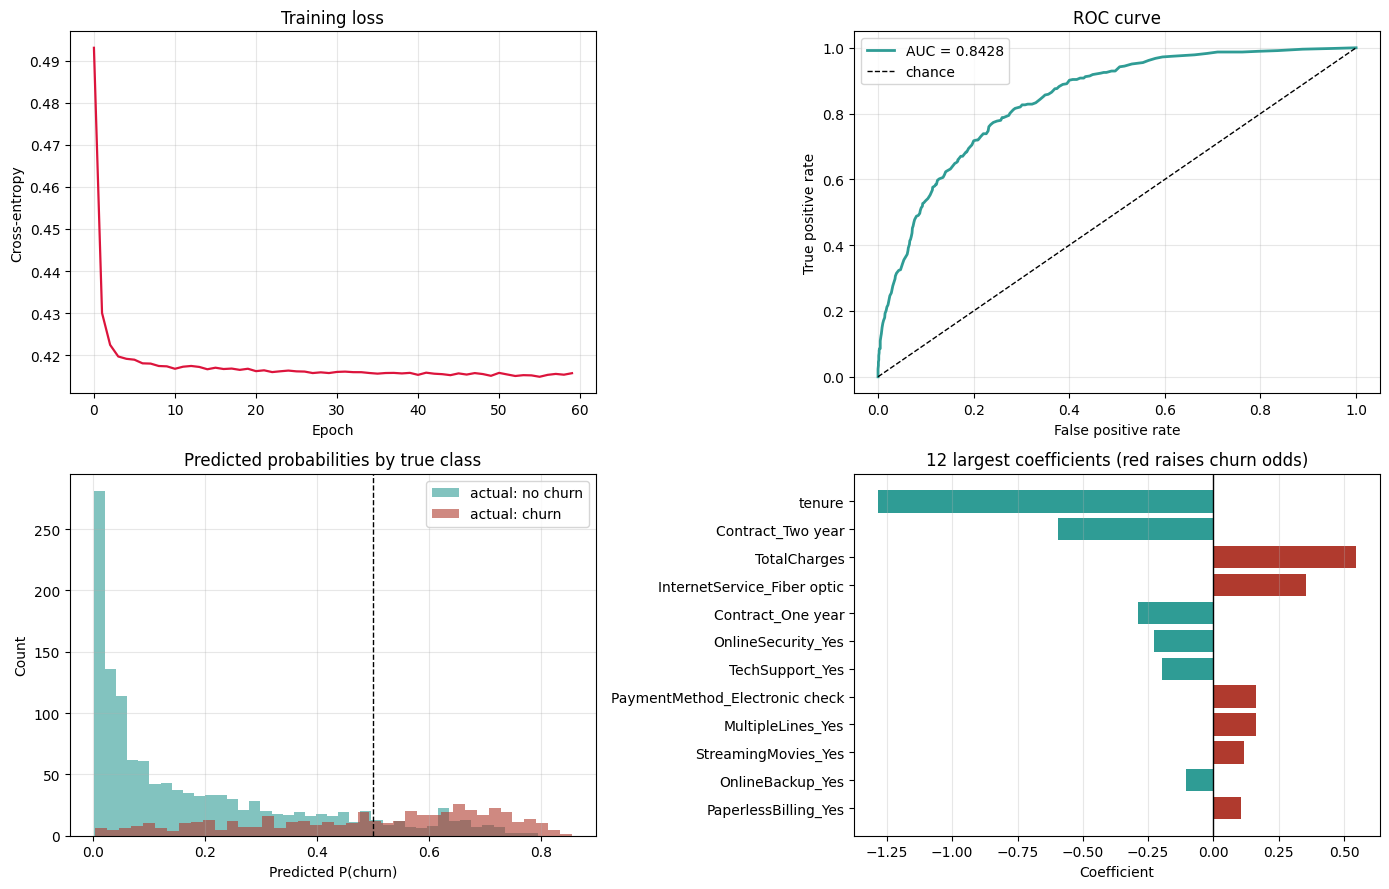

In [8]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
URL = ("https://raw.githubusercontent.com/IBM/"
       "telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv")
df = pd.read_csv(URL)
print("raw shape:", df.shape)

# TotalCharges arrives as text because 11 brand-new customers have a blank
# instead of a number. Coerce to numeric and fill those with 0, which is the
# correct value: they have been billed nothing yet (all have tenure == 0).
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("blank TotalCharges:", df['TotalCharges'].isna().sum(),
      "| their tenure values:", df.loc[df['TotalCharges'].isna(), 'tenure'].unique())
df['TotalCharges'] = df['TotalCharges'].fillna(0.0)

# customerID is an identifier, not a feature
df = df.drop(columns=['customerID'])

y = (df['Churn'] == 'Yes').astype(int).values
X_raw = df.drop(columns=['Churn'])

print("\n--- class balance ---")
print(f"  no churn (0): {(y==0).sum():5d}  ({(y==0).mean():.2%})")
print(f"  churn    (1): {(y==1).sum():5d}  ({(y==1).mean():.2%})")
print(f"  imbalance ratio: {(y==0).sum()/(y==1).sum():.2f} : 1")

# One-hot encode the categoricals, leave the three numerics alone
X = pd.get_dummies(X_raw, drop_first=True).astype(float)
feature_names = list(X.columns)
print(f"\nfeatures after one-hot encoding: {X.shape[1]}")

X_train, X_test, y_train, y_test = train_test_split(
    X.values, y, test_size=0.25, stratify=y)

# Standardise using TRAINING statistics only, so no test information leaks in
mu, sd = X_train.mean(0), X_train.std(0)
sd[sd == 0] = 1.0
X_train = (X_train - mu) / sd
X_test = (X_test - mu) / sd

print(f"train: {X_train.shape}   test: {X_test.shape}")

print("\n=== unweighted model ===")
model = LogisticRegression(n_features=X_train.shape[1],
                           learning_rate=0.1, epochs=60, batch_size=64)
model.fit(X_train, y_train)
m1 = model.evaluate(X_test, y_test)

print("\n=== class-weighted model (pos_weight = 2.79) ===")
pw = (y_train == 0).sum() / (y_train == 1).sum()
model_w = LogisticRegression(n_features=X_train.shape[1],
                             learning_rate=0.1, epochs=60, batch_size=64,
                             pos_weight=pw)
model_w.fit(X_train, y_train, verbose=False)
m2 = model_w.evaluate(X_test, y_test)

print("\n--- comparison ---")
print(f"{'metric':<20}{'unweighted':>12}{'weighted':>12}")
for k in ['accuracy', 'precision', 'recall', 'f1', 'balanced_accuracy', 'roc_auc']:
    print(f"{k:<20}{m1[k]:12.4f}{m2[k]:12.4f}")

print(f"\nmajority-class baseline accuracy: {(y_test==0).mean():.4f}")

model.plot_diagnostics(X_test, y_test, feature_names)